=== SO SÁNH ĐIỂM HẸN TỐI ƯU THEO TỪNG HÀM MỤC TIÊU ===
1. Sum (Tổng nhỏ nhất)         -> Đỉnh #1828  | Từng người: [7.9p, 0.1p, 10.1p, 10.1p] | Tổng: 28.2p | Max: 10.1p
2. Minimax (Công bằng nhất)    -> Đỉnh #1813  | Từng người: [8.7p, 3.5p, 8.7p, 8.8p] | Tổng: 29.7p | Max: 8.8p
3. Sum of Squares (Σ T²)       -> Đỉnh #11378 | Từng người: [11.4p, 4.9p, 5.7p, 6.7p] | Tổng: 28.7p | Max: 11.4p
4. Mean + 2*Std                -> Đỉnh #11378 | Từng người: [11.4p, 4.9p, 5.7p, 6.7p] | Tổng: 28.7p | Max: 11.4p
5. Weighted (Ưu tiên Phi x2)   -> Đỉnh #2935  | Từng người: [12.5p, 6.0p, 5.9p, 5.0p] | Tổng: 29.4p | Max: 12.5p

=== ĐƯỜNG BIÊN PARETO (Gồm 7 đỉnh tối ưu không bị trội) ===
  - Đỉnh #1828 : Tổng = 28.16 phút | Lâu nhất = 10.11 phút | Tọa độ: (10.78288, 106.69564)
  - Đỉnh #8315 : Tổng = 28.32 phút | Lâu nhất = 10.04 phút | Tọa độ: (10.78295, 106.69556)
  - Đỉnh #1827 : Tổng = 28.32 phút | Lâu nhất = 9.70 phút | Tọa độ: (10.78355, 106.69491)
  - Đỉnh #1671 : Tổng = 29.46 phút | Lâu nhất = 

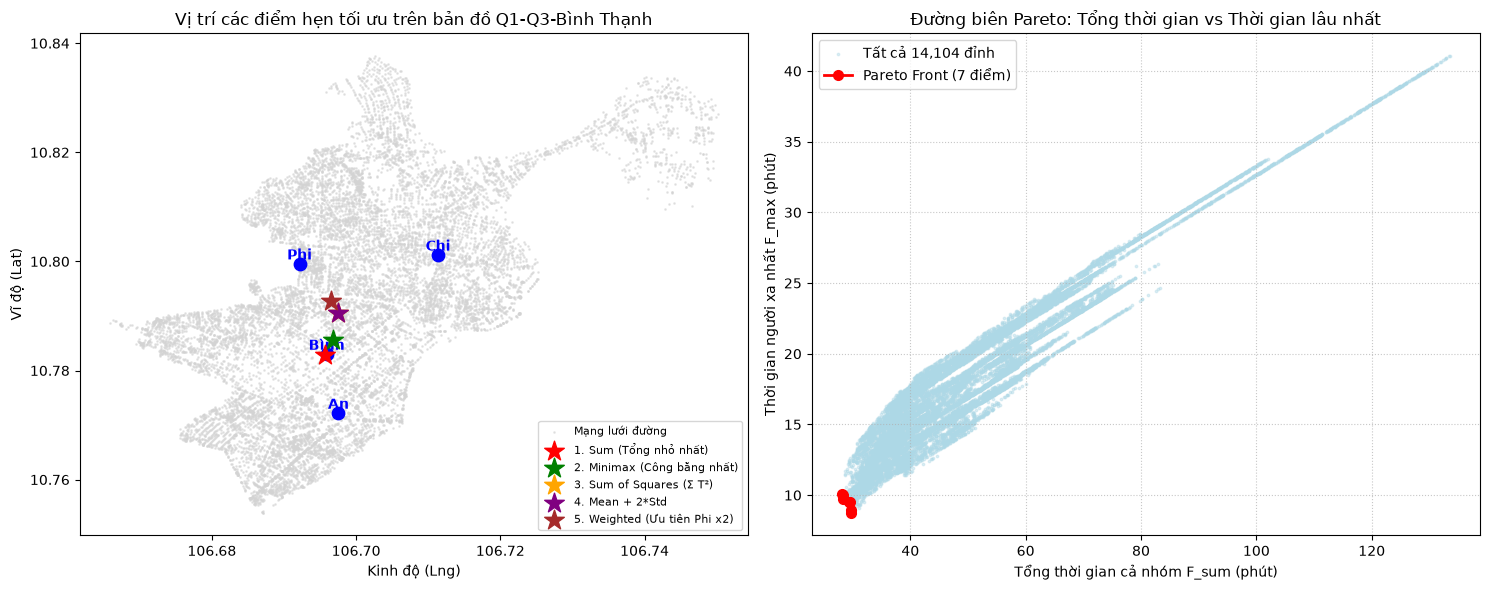

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from scipy.sparse.csgraph import dijkstra as scipy_dijkstra
from scipy.spatial import cKDTree

# 1. Nạp dữ liệu & Tính ma trận T (4 x 14104) tính bằng PHÚT cho dễ đọc
adj_matrix = load_npz("data/hcm_center_moto_adj.npz")
coords = np.load("data/hcm_center_moto_meta.npz")["coords"]
tree = cKDTree(coords)

people_gps = {
    "An (Chợ Bến Thành)": (10.7725, 106.6980),
    "Bình (Hồ Con Rùa)": (10.7827, 106.6959),
    "Chi (Hàng Xanh)": (10.8013, 106.7114),
    "Phi (Vạn Kiếp)": (10.7995, 106.6922),
}
source_indices = [tree.query(gps)[1] for gps in people_gps.values()]

# Đổi từ giây sang phút (/ 60.0)
T = scipy_dijkstra(csgraph=adj_matrix, directed=True, indices=source_indices) / 60.0

# 2. Tính các họ hàm mục tiêu F(v) trên toàn bộ 14,104 đỉnh bằng Vectorization
F_sum = np.sum(T, axis=0)
F_max = np.max(T, axis=0)
F_sq  = np.sum(T ** 2, axis=0)
F_std = F_sum + 2.0 * np.std(T, axis=0)  # Hệ số phạt lệch chuẩn lambda = 2.0

# Giả sử Phi (người thứ 4, index 3) cần ưu tiên gấp đôi (w = 2.0)
weights = np.array([1.0, 1.0, 1.0, 2.0])[:, None]
F_weighted = np.sum(T * weights, axis=0)

objectives = {
    "1. Sum (Tổng nhỏ nhất)": F_sum,
    "2. Minimax (Công bằng nhất)": F_max,
    "3. Sum of Squares (Σ T²)": F_sq,
    "4. Mean + 2*Std": F_std,
    "5. Weighted (Ưu tiên Phi x2)": F_weighted,
}

print("=== SO SÁNH ĐIỂM HẸN TỐI ƯU THEO TỪNG HÀM MỤC TIÊU ===")
opt_nodes = {}
for name, F_vals in objectives.items():
    best_v = int(np.argmin(F_vals))
    opt_nodes[name] = best_v
    times_str = ", ".join([f"{t:.1f}p" for t in T[:, best_v]])
    print(f"{name:<30} -> Đỉnh #{best_v:<5} | Từng người: [{times_str}] | Tổng: {F_sum[best_v]:.1f}p | Max: {F_max[best_v]:.1f}p")

# 3. Tìm Đường biên Pareto (Pareto Front) giữa F_sum và F_max
def find_pareto_front(sum_vals, max_vals):
    # Sắp xếp các đỉnh theo F_sum tăng dần, nếu bằng nhau thì xếp theo F_max tăng dần
    order = np.lexsort((max_vals, sum_vals))
    pareto_indices = []
    min_max_so_far = np.inf
    for idx in order:
        if max_vals[idx] < min_max_so_far:
            pareto_indices.append(int(idx))
            min_max_so_far = max_vals[idx]
    return pareto_indices

pareto_nodes = find_pareto_front(F_sum, F_max)
print(f"\n=== ĐƯỜNG BIÊN PARETO (Gồm {len(pareto_nodes)} đỉnh tối ưu không bị trội) ===")
for v in pareto_nodes:
    print(f"  - Đỉnh #{v:<5}: Tổng = {F_sum[v]:.2f} phút | Lâu nhất = {F_max[v]:.2f} phút | Tọa độ: ({coords[v][0]:.5f}, {coords[v][1]:.5f})")

# 4. Trực quan hóa: Bản đồ các điểm tối ưu (trái) & Đường biên Pareto (phải)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Biểu đồ 1: Vị trí địa lý các điểm tối ưu
axes[0].scatter(coords[:, 1], coords[:, 0], c='lightgray', s=1, alpha=0.5, label='Mạng lưới đường')
for person, idx in zip(people_gps.keys(), source_indices):
    axes[0].scatter(coords[idx, 1], coords[idx, 0], c='blue', s=80, zorder=4)
    axes[0].text(coords[idx, 1], coords[idx, 0] + 0.0008, person.split()[0], color='blue', fontweight='bold', ha='center')

colors = ['red', 'green', 'orange', 'purple', 'brown']
for (name, best_v), c in zip(opt_nodes.items(), colors):
    axes[0].scatter(coords[best_v, 1], coords[best_v, 0], c=c, marker='*', s=220, zorder=5, label=name)

axes[0].set_title("Vị trí các điểm hẹn tối ưu trên bản đồ Q1-Q3-Bình Thạnh")
axes[0].set_xlabel("Kinh độ (Lng)")
axes[0].set_ylabel("Vĩ độ (Lat)")
axes[0].legend(loc='lower right', fontsize=8)

# Biểu đồ 2: Không gian mục tiêu (F_sum vs F_max) và Đường biên Pareto
axes[1].scatter(F_sum, F_max, c='lightblue', s=3, alpha=0.4, label='Tất cả 14,104 đỉnh')
axes[1].plot(F_sum[pareto_nodes], F_max[pareto_nodes], 'ro-', linewidth=2, markersize=7, label=f'Pareto Front ({len(pareto_nodes)} điểm)')
axes[1].set_title("Đường biên Pareto: Tổng thời gian vs Thời gian lâu nhất")
axes[1].set_xlabel("Tổng thời gian cả nhóm F_sum (phút)")
axes[1].set_ylabel("Thời gian người xa nhất F_max (phút)")
axes[1].grid(True, linestyle=':', alpha=0.7)
axes[1].legend()

plt.tight_layout()
plt.show()